# (2) Example_MNIST_CNN_Load

Questo notebook contiene un esempio su come caricare una Convolutional Neural Network (CNN) giá allenarla per poterla poi usare per _inferenza_.

## 1. Setup and Imports

Importiamo le librarie che ci serviranno

In [2]:
# Importazione delle librerie fondamentali per il calcolo tensoriale e la gestione della rete neurale.
# L'ambiente delle dipendenze deve essere speculare a quello utilizzato durante la fase di addestramento.
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torchvision import datasets, transforms
from tqdm import tqdm

## 2. Data Preparation

Come per l'allenamento, é necessario avere accesso al dataset (e.g. MNIST) per fornirlo in ingresso alla rete.

In [3]:
# Inizializzazione, download (se mancante in locale) e partizionamento del dataset MNIST.

# Inference batch size
batch_size = 64

# Load the MNIST test set
mnist_test = datasets.MNIST("./", download=True, train=False,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Il DataLoader del test set fornisce i dati in ingresso durante l'inferenza.
# (Training e validation non servono qui: la rete è già addestrata.)

# Create test set loader
mnist_loader_test = torch.utils.data.DataLoader(mnist_test, batch_size=batch_size, shuffle=False)
N_test = len(mnist_loader_test.dataset)

## 3. Define the CNN Model

Se abbiamo una rete giá allenata, quello che é stato salvato sono i valori di tutte le variabili interne alla rete. Dobbiamo comunque definire nel nostro nuovo script o notebook la struttura della rete in modo che quando le variabili vengono caricate il compilatore Python sappia dove a cosa corrisponde ogni variabile. Nel seguito quindi la stessa ddefinizione di rete CNN che abbiamo usato nel training.

In [4]:
# Definizione della topologia della Rete Neurale Convoluzionale (CNN).
# È imperativo che l'architettura dichiarata in questa sede sia strutturalmente identica 
# a quella del modello originale, per consentire la perfetta mappatura dei pesi pre-addestrati.

# Define the CNN topology
def mnist_cnn():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Dropout(p=0.3),
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
        )

## 4. Training and Testing Functions

Anche se non ci serve piú esplicitamente per il training, il Wrapper che avevamo definito coniente anche un'interfaccia per il testing. É quindi conveniente e coerente ri-definirlo.
Ribadiamo che la definizione di una funzione Wrapper, per quanto non rara, non é di per sé uno standard nell'allenamento di reti in Pytorch. Resta comunque vantaggioso per poter poi utilizzare il framework Cross-Sim per In-Memory Computing.

In [5]:
# Istanziazione della classe "Wrapper" architetturale.
# Sebbene la fase di training venga totalmente bypassata, questa classe espone i metodi di "forward"
# necessari per propagare l'ingresso nella rete durante l'inferenza. Inoltre, mantiene la 
# standardizzazione necessaria per l'interfacciamento con Cross-Sim nel notebook successivo.

# Wrapper for training the CNN
class SequentialWrapper():
    def __init__(self, net, loss, learning_rate=1e-3):
        self.net = net
        self.loss = loss
        self.learning_rate = learning_rate
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=self.learning_rate)

    def forward(self, x):
        return self.net(x)
    
    def training_step(self, batch):
        self.optimizer.zero_grad()
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        loss.backward()
        self.optimizer.step()
        return loss

    def validation_step(self, batch):
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        return loss
    
    def train_epoch(self, train_loader, val_loader):
        loss_train, loss_val = 0, 0
        for minibatch in iter(train_loader):
            loss_train += self.training_step(minibatch).detach()
        for minibatch in iter(val_loader):
            loss_val += self.validation_step(minibatch).detach()
        return loss_train/len(train_loader), loss_val/len(val_loader)
    
    def train(self, train_loader, val_loader, epochs):
        loss_train, loss_val = np.zeros(epochs), np.zeros(epochs)
        for e in tqdm(range(0, epochs)):
            lt, lv = self.train_epoch(train_loader, val_loader)
            loss_train[e] = lt
            loss_val[e] = lv
        return loss_train, loss_val

# Create the wrapped PyTorch model
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())

## 5. Load Trained Network

Una volta ri-definita la struttura della rete uguale a quella che é stata allenata, possiamo leggere le variabili ottenute alla fine del _training_.


In [6]:
# Caricamento dello "State Dict" dal file locale "trained_mnist_cnn_dropout_v2.pt".
# Questa operazione sovrascrive i pesi sinaptici inizializzati casualmente dalla funzione precedente 
# con i parametri esatti derivati dalla fase di addestramento, ripristinando il "cervello" della rete.

mnist_cnn_pt.net.load_state_dict(torch.load('trained_mnist_cnn_dropout_v2.pt', map_location='cpu', weights_only=True))

# Il modello viene messo in modalità inferenza (eval) UNA SOLA VOLTA, subito dopo il caricamento.
# Una rete appena creata è in modalità "train": il Dropout sarebbe ATTIVO e ogni inferenza darebbe un
# risultato diverso. Da qui in poi (sezioni 5, 6 e 7) il Dropout resta spento, senza ripetere eval().
mnist_cnn_pt.net.eval()


Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(2, 2), padding=valid)
  (1): ReLU()
  (2): Conv2d(8, 16, kernel_size=(3, 3), stride=(2, 2), padding=valid)
  (3): ReLU()
  (4): Flatten(start_dim=1, end_dim=-1)
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=576, out_features=16, bias=True)
  (7): ReLU()
  (8): Linear(in_features=16, out_features=10, bias=True)
)

Testiamo con un'_inferenza_ che le variabili siano state caricate correttamente.
Poiché stiamo usando lo stesso subset dei dati (_testing_) ci aspettiamo la stessa accuratezza ottenuta alla fine del notebook `Example_MNIST_CNN_Train`.

In [7]:
# Esecuzione dell'inferenza sul set di immagini di test per validare il corretto ripristino del modello.

# CORREZIONE - Le liste partono vuote. Nella versione precedente gli array partivano con 10.000 zeri
# (np.zeros(N_test)) che venivano contati come predizioni corrette, gonfiando l'accuratezza
# (accuracy_vera = 2 * accuracy_stampata - 1).
y_pred_list, y_list = [], []
for inputs, labels in mnist_loader_test:
    with torch.no_grad():
        output = mnist_cnn_pt.net(inputs)
        y_pred_list.append(output.argmax(dim=-1).numpy())
        y_list.append(labels.argmax(dim=1).numpy())

y_pred = np.concatenate(y_pred_list)
y = np.concatenate(y_list)

# L'accuratezza restituita funge da test di integrità: deve corrispondere a quella
# ottenuta al termine dell'addestramento nel notebook (1), confermando l'assenza di corruzione dei dati.

# Evaluate accuracy
accuracy_digitalTrain_digitalTest = np.sum(y == y_pred)/len(y)
print('===========')
print('No analog errors during training, no analog errors during test')
print('Test accuracy: {:.2f}%\n'.format(accuracy_digitalTrain_digitalTest*100))

No analog errors during training, no analog errors during test
Test accuracy: 98.55%



## 6. Analisi degli Errori e Livello di Indecisione

Una volta valutata l'accuratezza globale, è utile osservare visivamente quali immagini la rete neurale ha "sbagliato" a classificare. 

Per andare più a fondo, in questo blocco non ci limitiamo a mostrare l'etichetta predetta, ma calcoliamo la **distribuzione di probabilità (Softmax)** per ogni errore. In questo modo possiamo capire se l'errore deriva da una forte indecisione del modello (percentuali vicine tra la risposta vera e quella sbagliata) o se l'intrinseca ambiguità della grafia ha letteralmente "ingannato" la rete, portandola a un'alta percentuale di sicurezza sulla cifra errata.

Totale errori riscontrati: 145 su 10000 immagini di test.


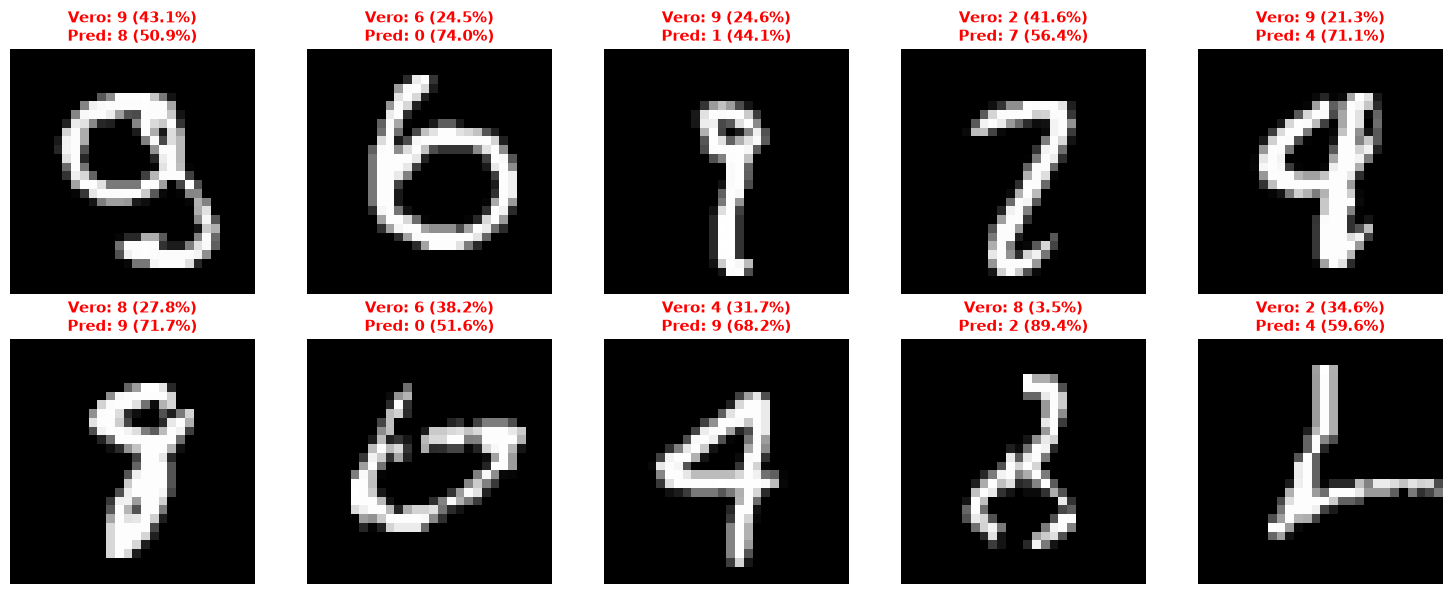

In [8]:
# Estrazione e analisi visiva delle "Misclassifications".
# Isola e decodifica i campioni del test set su cui la rete ha fallito la predizione.
# Permette un'indagine qualitativa per capire se l'errore deriva da limiti del classificatore 
# o dall'intrinseca ambiguità della grafia umana nel campione specifico.

# Etichette reali e predizioni (gli array contengono solo i 10.000 campioni di test)
y_real = y
y_predicted = y_pred

# Trova gli indici in cui la predizione non corrisponde al valore reale
error_indices = np.where(y_real != y_predicted)[0]

print(f"Totale errori riscontrati: {len(error_indices)} su {len(y_real)} immagini di test.")

# Quante immagini errate vogliamo visualizzare
num_images_to_show = 10

# Crea un layout a griglia (2 righe, 5 colonne) per evitare sovrapposizioni
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten() # Appiattisce la matrice degli assi per iterarci facilmente

for i, idx in enumerate(error_indices[:num_images_to_show]):
    image, _ = mnist_test[idx]
    image_np = image.squeeze().numpy()
    
    # --- CALCOLO DELLE PERCENTUALI DI INDECISIONE (SOFTMAX) ---
    # Adattiamo le dimensioni dell'immagine per la rete: da (1, 28, 28) a (1, 1, 28, 28)
    image_tensor = image.unsqueeze(0)
    
    with torch.no_grad():
        logits = mnist_cnn_pt.net(image_tensor)
        # Trasformiamo i risultati grezzi in probabilità da 0 a 100%
        probabilities = F.softmax(logits, dim=1).squeeze().numpy()
        
    true_class = int(y_real[idx])
    pred_class = int(y_predicted[idx])
    
    # Estraiamo quanto era sicura della scelta sbagliata e quanto aveva assegnato a quella corretta
    conf_pred = probabilities[pred_class] * 100
    conf_true = probabilities[true_class] * 100
    
    # --- DISEGNO IMMAGINE E TITOLO ---
    axes[i].imshow(image_np, cmap='gray')
    
    # Titolo su due righe: mostra il valore Vero (con la sua %) e il Predetto (con la sua %)
    title_str = f"Vero: {true_class} ({conf_true:.1f}%)\nPred: {pred_class} ({conf_pred:.1f}%)"
    
    axes[i].set_title(title_str, color='red', fontsize=11, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 7. Inferenza Live (Lavagna Interattiva)

Ora che abbiamo testato la rete su immagini pre-esistenti, mettiamola alla prova in tempo reale. 
Qui sotto è stata creata una "lavagna" interattiva. Disegna un numero da 0 a 9 con il mouse e clicca su **Classifica**.

Il codice estrae il disegno, lo ritaglia sulla cifra, lo scala in un riquadro 20x20 e lo centra in un'immagine 28x28 (come fanno le immagini MNIST), lo normalizza e lo passa alla rete. Inoltre, applicando la funzione **Softmax** all'output della rete, possiamo osservare la "distribuzione delle probabilità", ovvero capire con quanta sicurezza la rete ha preso la sua decisione e su quali altre cifre era eventualmente indecisa.

In [11]:
# ==========================================
# 7. Inferenza Live (Finestra Pop-up Nativa 3D)
# ==========================================
import tkinter as tk
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.figure import Figure
from PIL import Image, ImageDraw

# --- FUNZIONI DI SUPPORTO PER GRAFICA ARROTONDATA ---
def create_rounded_rect(canvas, x1, y1, x2, y2, radius=20, **kwargs):
    """Disegna un rettangolo con bordi arrotondati tramite coordinate poligonali smussate."""
    points = [x1+radius, y1, x1+radius, y1, x2-radius, y1, x2-radius, y1,
              x2, y1, x2, y1+radius, x2, y1+radius, x2, y2-radius, x2, y2-radius,
              x2, y2, x2-radius, y2, x2-radius, y2, x1+radius, y2, x1+radius, y2,
              x1, y2, x1, y2-radius, x1, y2-radius, x1, y1+radius, x1, y1+radius, x1, y1]
    
    # Rimuove il bordo nero di default di Tkinter
    if 'outline' not in kwargs:
        kwargs['outline'] = ""
        
    return canvas.create_polygon(points, **kwargs, smooth=True)

class RoundedButton(tk.Canvas):
    """Classe personalizzata per creare bottoni tondeggianti con effetto click 3D."""
    def __init__(self, parent, width, height, text, bg_color, fg_color, command):
        super().__init__(parent, width=width, height=height, bg='#e8e8e8', highlightthickness=0)
        self.command = command
        # Ombra del bottone (grigio scuro, spostata in basso). Raggio ottimizzato a 20.
        self.shadow = create_rounded_rect(self, 2, 4, width-2, height, radius=20, fill='#cccccc')
        # Corpo centrale del bottone
        self.rect = create_rounded_rect(self, 2, 2, width-2, height-2, radius=20, fill=bg_color)
        self.text = self.create_text(width//2, height//2, text=text, fill=fg_color, font=("Helvetica", 12, "bold"))
        
        # Colleghiamo gli eventi del mouse
        self.bind("<ButtonPress-1>", self.on_press)
        self.bind("<ButtonRelease-1>", self.on_release)

    def on_press(self, event):
        # Quando clicchi, il corpo e il testo scendono di 2 pixel coprendo l'ombra
        self.move(self.rect, 0, 2)
        self.move(self.text, 0, 2)

    def on_release(self, event):
        # Quando rilasci, tornano su ed esegue il comando
        self.move(self.rect, 0, -2)
        self.move(self.text, 0, -2)
        self.command()


# --- PRE-ELABORAZIONE DEL DISEGNO (stile MNIST) ---
# Le cifre MNIST sono ritagliate, scalate in un riquadro 20x20 (proporzioni mantenute) e centrate
# nel 28x28 usando il baricentro. Senza questo passaggio un disegno a tutta lavagna, decentrato,
# viene riconosciuto peggio anche se la rete e' ottima.
def shift_image(img, dy, dx):
    out = np.zeros_like(img)
    out[max(0, dy):min(28, 28 + dy), max(0, dx):min(28, 28 + dx)] = \
        img[max(0, -dy):min(28, 28 - dy), max(0, -dx):min(28, 28 - dx)]
    return out

def preprocess_drawing(img_pil):
    arr = np.array(img_pil)
    ys, xs = np.nonzero(arr > 0)
    if len(xs) == 0:
        return None                                   # lavagna vuota
    arr = arr[ys.min():ys.max() + 1, xs.min():xs.max() + 1]   # ritaglio sulla cifra
    h, w = arr.shape
    scale = 20.0 / max(h, w)                          # il lato piu' lungo diventa 20 pixel
    new_w, new_h = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    digit = Image.fromarray(arr).resize((new_w, new_h), Image.Resampling.LANCZOS)
    img28 = np.zeros((28, 28), dtype=np.float32)
    top, left = (28 - new_h) // 2, (28 - new_w) // 2
    img28[top:top + new_h, left:left + new_w] = np.array(digit, dtype=np.float32)
    # centratura con il baricentro (come in MNIST)
    total = img28.sum()
    cy = (img28.sum(axis=1) * np.arange(28)).sum() / total
    cx = (img28.sum(axis=0) * np.arange(28)).sum() / total
    img28 = shift_image(img28, int(round(13.5 - cy)), int(round(13.5 - cx)))
    return np.clip(img28, 0, 255)


# --- SETUP VARIABILI ---
canvas_size = 400 
last_x, last_y = None, None

img_pil = Image.new("L", (canvas_size, canvas_size), color=0)
draw_mem = ImageDraw.Draw(img_pil)

# --- CREAZIONE FINESTRA POP-UP ---
root = tk.Tk()
root.title("Classificatore MNIST In-Memory Computing")
root.geometry("1200x520")
root.configure(bg='#e8e8e8')
root.resizable(False, False)

# --- LAYOUT A COLONNE ---
left_frame = tk.Frame(root, width=550, height=550, bg='#e8e8e8')
left_frame.pack(side=tk.LEFT, fill=tk.BOTH, expand=True, padx=20, pady=20)

right_frame = tk.Frame(root, width=400, height=550, bg='#e8e8e8')
right_frame.pack(side=tk.RIGHT, fill=tk.BOTH, padx=20, pady=20)

# --- COLONNA SINISTRA: GRAFICO E TESTO ---
lbl_result = tk.Label(left_frame, text="Disegna una cifra a destra!", font=("Helvetica", 14, "bold"), bg='#e8e8e8', fg='#333333')
lbl_result.pack(pady=(0, 10))

fig = Figure(figsize=(6, 4.5))
fig.patch.set_facecolor('#e8e8e8')
ax = fig.add_subplot(111)
ax.set_facecolor('white')

ax.tick_params(colors='black')
ax.spines['bottom'].set_color('black')
ax.spines['left'].set_color('black')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylim(0, 100)
ax.set_ylabel('Probabilità (%)', color='black')
ax.set_xlabel('Cifre (0-9)', color='black')
ax.set_title('Distribuzione Softmax', fontweight='bold', color='black')
fig.tight_layout()

canvas_matplot = FigureCanvasTkAgg(fig, master=left_frame)
canvas_matplot.get_tk_widget().pack()

# --- COLONNA DESTRA: LAVAGNA ARROTONDATA ---
cv = tk.Canvas(right_frame, width=canvas_size, height=canvas_size, bg='#e8e8e8', cursor="cross", highlightthickness=0)
cv.pack(pady=(0, 20))
# Disegniamo il quadrato nero con gli angoli smussati senza bordo nero
create_rounded_rect(cv, 0, 0, canvas_size, canvas_size, radius=35, fill='black')

def paint(event):
    global last_x, last_y
    x, y = event.x, event.y
    if last_x is not None and last_y is not None:
        cv.create_line((last_x, last_y, x, y), width=24, fill='white', capstyle=tk.ROUND, smooth=tk.TRUE)
        draw_mem.line([last_x, last_y, x, y], fill=255, width=24, joint='curve')
    last_x, last_y = x, y

def reset(event):
    global last_x, last_y
    last_x, last_y = None, None

cv.bind("<B1-Motion>", paint)
cv.bind("<ButtonRelease-1>", reset)

# --- FUNZIONI DEI BOTTONI ---
def clear():
    cv.delete("all")
    create_rounded_rect(cv, 0, 0, canvas_size, canvas_size, radius=35, fill='black')
    draw_mem.rectangle([0, 0, canvas_size, canvas_size], fill=0)
    
    ax.clear()
    ax.set_facecolor('white')
    ax.tick_params(colors='black')
    ax.spines['bottom'].set_color('black')
    ax.spines['left'].set_color('black')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.set_ylim(0, 100)
    ax.set_ylabel('Probabilità (%)', color='black')
    ax.set_xlabel('Cifre (0-9)', color='black')
    ax.set_title('Distribuzione Softmax', fontweight='bold', color='black')
    fig.tight_layout()
    canvas_matplot.draw()
    lbl_result.config(text="Lavagna pulita. Disegna!", fg='#333333')

def predict():
    try:
        mnist_cnn_pt
    except NameError:
        lbl_result.config(text="Errore: Rete non caricata in memoria!", fg="#ff4d4d")
        return

    img_small = preprocess_drawing(img_pil)

    if img_small is None:
        lbl_result.config(text="Errore: Lavagna vuota!", fg="#ff4d4d")
        return

    img_tensor = torch.tensor(img_small, dtype=torch.float32) / 255.0
    img_tensor = (img_tensor - 0.1307) / 0.3081
    img_tensor = img_tensor.unsqueeze(0).unsqueeze(0)

    with torch.no_grad():
        logits = mnist_cnn_pt.net(img_tensor)
        probabilities = F.softmax(logits, dim=1).squeeze().numpy()

    predicted_digit = np.argmax(probabilities)
    confidence = probabilities[predicted_digit] * 100

    lbl_result.config(text=f"Cifra: {predicted_digit} (Sicurezza: {confidence:.2f}%)", fg="#2ca02c")

    ax.clear()
    ax.set_facecolor('white')
    ax.tick_params(colors='black')
    ax.spines['bottom'].set_color('black')
    ax.spines['left'].set_color('black')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    classes = np.arange(10)
    colors = ['#1f77b4' if i != predicted_digit else '#2ca02c' for i in classes]
    
    bars = ax.bar(classes, probabilities * 100, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(classes)
    ax.set_ylabel('Probabilità (%)', color='black')
    ax.set_xlabel('Cifre (0-9)', color='black')
    ax.set_title('Distribuzione Softmax', fontweight='bold', color='black')
    ax.set_ylim(0, 115)
    
    ax.grid(axis='y', linestyle='--', alpha=0.4, color='gray')
    ax.set_axisbelow(True)

    for bar in bars:
        height = bar.get_height()
        if height > 0.5:
            ax.text(bar.get_x() + bar.get_width()/2, height + 2, f'{height:.1f}%', va='bottom', ha='center', fontsize=9, color='black')

    fig.tight_layout()
    canvas_matplot.draw()

# --- BOTTONI CUSTOM (Tondeggianti e Interattivi) ---
btn_frame = tk.Frame(right_frame, bg='#e8e8e8')
btn_frame.pack()

btn_pred = RoundedButton(btn_frame, width=130, height=45, text="🎯 Classifica", bg_color='#5cb85c', fg_color='white', command=predict)
btn_pred.pack(side=tk.LEFT, padx=10)

btn_clr = RoundedButton(btn_frame, width=130, height=45, text="🗑️ Pulisci", bg_color='#f0ad4e', fg_color='white', command=clear)
btn_clr.pack(side=tk.LEFT, padx=10)

root.mainloop()